**Lab 4** for the course of *Selected Topics in Music and Acoustic Engineering* :

***Machine Learning for Audio and Acoustic Engineering***
---

* Student 1: Jorge Cuartero Galindo
* Student 2: Giuliano Di Lorenzo

# **Before you start**

*   Go to "*File*" --> "*Save a copy in Drive*"
*   Open that copy (might open automatically)
*   Then continue below

# **Lab 4: Neural Networks (II)**
---

In this lab we will continue exploring different types of deep architectures for audio processing, and we will pay special attention to system evaluation.


In [1]:
# As always, we import the relevant packages
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import librosa
import sklearn
import tensorflow as tf
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import pandas as pd
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
plt.style.use("seaborn-v0_8")

import keras
from keras import layers

### **Exercise 1**: Data Preparation I

We will continue working with the ESC-50 dataset. Download it to your notebook following the same steps as in Lab 2 and Lab 3.

In [ ]:
#!wget https://github.com/karolpiczak/ESC-50/archive/master.zip
#!unzip master.zip

--2025-05-14 17:57:15--  https://github.com/karolpiczak/ESC-50/archive/master.zip
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master [following]
--2025-05-14 17:57:15--  https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master
Resolving codeload.github.com (codeload.github.com)... 140.82.114.9
Connecting to codeload.github.com (codeload.github.com)|140.82.114.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 645695005 (616M) [application/zip]
Saving to: ‘master.zip’

master.zip          100%[===================>] 615.78M  53.7MB/s    in 12s     

2025-05-14 17:57:28 (50.4 MB/s) - ‘master.zip’ saved [645695005/645695005]

Archive:  master.zip
33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6
   creating: ESC-50-master/
   creating: ESC-50-master/.circleci/
  infla

Create a list containing the audio files and another one with the corresponding labels (as in Lab 3):

In [3]:
# YOUR CODE HERE!
# fn_csv = 'ESC-50-master/meta/esc50.csv'
fn_csv = '../ESC-50-master/meta/esc50.csv'
df = pd.read_csv(fn_csv)

files = np.array(df['filename'].tolist())
labels = np.array(df['target'].tolist())

print(f'Lenghts: esc5_X: {len(files)}, esc5_y: {len(labels)}')

Lenghts: esc5_X: 2000, esc5_y: 2000


In [4]:
print(files)

['1-100032-A-0.wav' '1-100038-A-14.wav' '1-100210-A-36.wav' ...
 '5-51149-A-25.wav' '5-61635-A-8.wav' '5-9032-A-0.wav']


Instead of working with 50 classes, we limit our dataset to only 10 classes. Filter you two files (the one with file paths and the one with labels) to contain only those belonging to classes [0-9].

In [5]:
# YOUR CODE HERE!
df_10_classes = df[df['target'] < 10]   # take the first 10 classes

files = files[(labels<10)]
labels = labels[labels<10]

print(f'Lenghts: esc5_X: {len(files)}, esc5_y: {len(labels)}')

Lenghts: esc5_X: 400, esc5_y: 400


We load the signals and get the Mel spectrogram for each signal. Create a list called "signals" storing the raw waveforms of each file in your list and another one called "melspecs" that stores the Mel spectrogram for each signal.

Note: use the default parameters for librosa.load (resample to 22050Hz) and librosa.feature.melspectrogram.

In [6]:
# YOUR CODE HERE!
# path = 'ESC-50-master/audio/'
path = '../ESC-50-master/audio/'
sr = librosa.get_samplerate(path + files[0])
signals = [librosa.load(path + file)[0] for file in files]

melspecs = [librosa.feature.melspectrogram(y=sig,sr=22050) for sig in signals]

### **Exercise 2**: Data preparation II



Convert your "melspecs" and "labels" list to numpy arrays, called "Xdata" and "Ydata".
Check that the result has size (400, 128, 216) for Xdata and (400,) for Ydata.

In [7]:
# YOUR CODE HERE!
Xdata = np.asarray(melspecs)
Ydata = np.asarray(labels)

print('Xdata shape: {} \nYata shape: {}'.format(Xdata.shape, Ydata.shape))

Xdata shape: (400, 128, 216) 
Yata shape: (400,)


Check that Ydata is balanced by plotting the histogram.

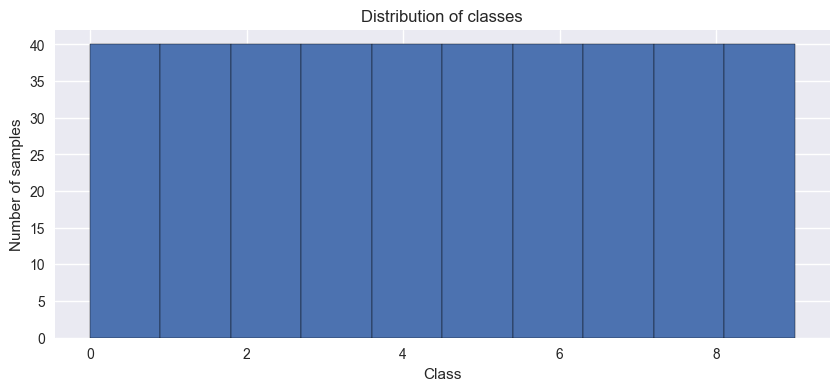

In [8]:
# YOUR CODE HERE!
plt.figure(figsize=(10, 4))
plt.title('Distribution of classes')
plt.hist(Ydata, edgecolor='black')
plt.xlabel('Class')
plt.ylabel('Number of samples')
plt.show()

Split your dataset into 3 partitions, 1 for training (70%), 1 for validation (20%) and 1 for test (10%). Check that the resulting arrays have the correct shape:

In [27]:
# YOUR CODE HERE!
X_train, X_temp, y_train, y_temp = train_test_split(Xdata, Ydata, test_size=0.3)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3)

# Shapes for each partition
print('X_train shape: {} \nX_val shape: {} \nX_test shape: {} \ny_train shape: {} \ny_val shape: {} \ny_test shape: {} \n'.format(X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape))

X_train shape: (280, 128, 216) 
X_val shape: (80, 128, 216) 
X_test shape: (40, 128, 216) 
y_train shape: (280,) 
y_val shape: (80,) 
y_test shape: (40,) 



Expected output:
```
X_train shape: (280, 128, 216)
X_val shape: (80, 128, 216)
X_test shape: (40, 128, 216)
y_train shape: (280,)
y_val shape: (80,)
y_test shape: (40,)
```

In the next exercise we will create a time-distributed 1D-CNN to process our dataset. By default, Keras assumes that the last dimension corresponds to the number of channels in our input. Since we are going to use 1D-CNN, each frequency band will be processed as an independent frequency channel. Therefore, we need to reorder the dimensions in our data to move the frequency channels to the last dimension.

Use the numpy function "moveaxis" to create the data matrices X_train_rs, X_val_rs and X_test_rs, with dimensions (280, 216, 128), (80, 216, 128) and (40, 216, 128):

In [28]:
# YOUR CODE HERE!
X_train_rs = np.moveaxis(X_train, 1, 2)
X_val_rs = np.moveaxis(X_val, 1, 2)
X_test_rs = np.moveaxis(X_test, 1, 2)

print('X_train_rs shape: {} \nX_val_rs shape: {} \nX_test_rs shape: {}'.format(X_train_rs.shape, X_val_rs.shape, X_test_rs.shape))

X_train_rs shape: (280, 216, 128) 
X_val_rs shape: (80, 216, 128) 
X_test_rs shape: (40, 216, 128)


Expected output:
```
X_train_rs shape: (280, 216, 128)
X_val_rs shape: (80, 216, 128)
X_test_rs shape: (40, 216, 128)
```

### **Exercise 3**: 1D-Convolutional Neural Network



Create the following 1D-CNN architecture with Keras:

1. **Input**  Shape: `(timesteps, features)`

2. **Conv1D**  `16 filters, kernel=9, ReLU`

3. **MaxPool1D**  `Pool=2, padding=same`

4. **BatchNorm**

5. **Conv1D**  `16 filters, kernel=3, ReLU`

6. **MaxPool1D**  `Pool=2, padding=same`

7. **BatchNorm**

8. **Conv1D**  `32 filters, kernel=3, ReLU`

9. **MaxPool1D**  `Pool=2, padding=same`

10. **BatchNorm**

11. **Flatten**

12. **Dense**  `32 units, ReLU`

13. **Dense**  `10 units, Softmax`


In [63]:
# YOUR CODE HERE!
model = keras.Sequential([
    layers.Input(shape=(X_train_rs.shape[1], X_train_rs.shape[2])),

    layers.Conv1D(filters=16, kernel_size=9, activation='relu'),
    layers.MaxPooling1D(pool_size=2, padding='same'),

    layers.BatchNormalization(),

    layers.Conv1D(filters=16, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2, padding='same'),

    layers.BatchNormalization(),

    layers.Conv1D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2, padding='same'),

    layers.BatchNormalization(),
    layers.Flatten(),

    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)               │ (None, 208, 16)        │        18,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_9 (MaxPooling1D)  │ (None, 104, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 104, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 102, 16)        │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_10 (MaxPooling1D) │ (None, 51, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 51, 16)         │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 49, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_11 (MaxPooling1D) │ (None, 25, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 25, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,018 (183.66 KB)

 Trainable params: 46,890 (183.16 KB)

 Non-trainable params: 128 (512.00 B)

Iniatialize Keras Callbacks:

*   CSVLogger.
*   Early_Stop with patience 100 epochs, working on validation loss.
*   ModelCheckpoint working on validation accuracy (monitor = 'val_accuracy').

In [64]:
# YOUR CODE HERE!
# csv logger
csv_logger = CSVLogger('training_model.log', append=False)

# early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=100)

# model checkpoint
model_name = 'best_model.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

#store all these callbacks in a list, Callback list
callbacks = [csv_logger, early_stopping, model_checkpoint]

Train the network using Adam optimizer with `learning_rate=0.001` and a `batch_size=32`. Remember to include the created callbacks.

In [65]:
# YOUR CODE HERE!
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train_rs, y_train,
    validation_data=(X_val_rs, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.0938 - loss: 2.3783
Epoch 1: val_accuracy improved from -inf to 0.21250, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.1304 - loss: 2.5063 - val_accuracy: 0.2125 - val_loss: 2.3701
Epoch 2/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4062 - loss: 1.8286
Epoch 2: val_accuracy improved from 0.21250 to 0.25000, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3589 - loss: 1.8680 - val_accuracy: 0.2500 - val_loss: 2.1978
Epoch 3/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5000 - loss: 1.7105
Epoch 3: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5158 - loss: 1.5858 - val_accuracy: 0.2375 - val_loss: 2.1560
Epoch 4/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6562 - loss: 1.3356
Epoch 4: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6028 - loss: 1.3121 - val_accuracy: 0.2250 - val_loss: 2.1665
Epoch 5/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5938 - loss: 1.2924
Epoch 5: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6825 - loss: 1.1483 - val_accuracy: 0.2125 - val_loss: 2.1650
Epoch 6/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5938 - loss: 1.2110
Epoch 6: val_accuracy did not improve from 0.25000
9

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9503 - loss: 0.2475 - val_accuracy: 0.2625 - val_loss: 2.3679
Epoch 23/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8438 - loss: 0.4571
Epoch 23: val_accuracy improved from 0.26250 to 0.27500, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9318 - loss: 0.2715 - val_accuracy: 0.2750 - val_loss: 2.3489
Epoch 24/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9375 - loss: 0.1624
Epoch 24: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9489 - loss: 0.1902 - val_accuracy: 0.2750 - val_loss: 2.3558
Epoch 25/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9062 - loss: 0.3278
Epoch 25: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9447 - loss: 0.2438 - val_accuracy: 0.2625 - val_loss: 2.4249
Epoch 26/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9688 - loss: 0.1413
Epoch 26: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9339 - loss: 0.2087 - val_accuracy: 0.2750 - val_loss: 2.4168
Epoch 27/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9375 - loss: 0.1814
Epoch 27: val_accuracy did not improve from 0.

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9459 - loss: 0.1861 - val_accuracy: 0.2875 - val_loss: 2.6119
Epoch 30/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9375 - loss: 0.2209
Epoch 30: val_accuracy improved from 0.28750 to 0.30000, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9552 - loss: 0.1755 - val_accuracy: 0.3000 - val_loss: 2.4938
Epoch 31/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9375 - loss: 0.2145
Epoch 31: val_accuracy did not improve from 0.30000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9625 - loss: 0.1593 - val_accuracy: 0.2875 - val_loss: 2.6665
Epoch 32/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.0662
Epoch 32: val_accuracy did not improve from 0.30000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9673 - loss: 0.1382 - val_accuracy: 0.2750 - val_loss: 2.5574
Epoch 33/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.0845
Epoch 33: val_accuracy did not improve from 0.30000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9783 - loss: 0.1361 - val_accuracy: 0.2750 - val_loss: 2.5499
Epoch 34/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9688 - loss: 0.1988
Epoch 34: val_accuracy did not improve from 0

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9868 - loss: 0.0812 - val_accuracy: 0.3250 - val_loss: 2.9736
Epoch 51/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9688 - loss: 0.0677
Epoch 51: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9761 - loss: 0.0925 - val_accuracy: 0.3125 - val_loss: 2.8556
Epoch 52/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9688 - loss: 0.0883
Epoch 52: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9680 - loss: 0.1097 - val_accuracy: 0.2875 - val_loss: 3.0043
Epoch 53/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 0.0099
Epoch 53: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9693 - loss: 0.0890 - val_accuracy: 0.2750 - val_loss: 2.9578
Epoch 54/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 0.0327
Epoch 54: val_accuracy did not improve from 0

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9828 - loss: 0.0626 - val_accuracy: 0.3500 - val_loss: 2.9593
Epoch 67/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9688 - loss: 0.0875
Epoch 67: val_accuracy did not improve from 0.35000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9821 - loss: 0.0600 - val_accuracy: 0.3500 - val_loss: 3.0213
Epoch 68/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 1.0000 - loss: 0.0305
Epoch 68: val_accuracy did not improve from 0.35000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9934 - loss: 0.0382 - val_accuracy: 0.3250 - val_loss: 3.2358
Epoch 69/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9688 - loss: 0.1125
Epoch 69: val_accuracy did not improve from 0.35000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9872 - loss: 0.0628 - val_accuracy: 0.3125 - val_loss: 3.0975
Epoch 70/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9688 - loss: 0.0482
Epoch 70: val_accuracy did not improve from 

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9973 - loss: 0.0339 - val_accuracy: 0.3625 - val_loss: 3.4419
Epoch 95/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.0136
Epoch 95: val_accuracy did not improve from 0.36250
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9952 - loss: 0.0231 - val_accuracy: 0.3625 - val_loss: 3.3992
Epoch 96/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9688 - loss: 0.0894
Epoch 96: val_accuracy did not improve from 0.36250
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9881 - loss: 0.0431 - val_accuracy: 0.3250 - val_loss: 3.5796
Epoch 97/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.0082
Epoch 97: val_accuracy did not improve from 0.36250
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9915 - loss: 0.0201 - val_accuracy: 0.3375 - val_loss: 3.5112
Epoch 98/1000
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 98: val_accuracy did not improve from 

From the log file, using pandas, plot the training history including accuracy and loss. What is your best validation accuracy?

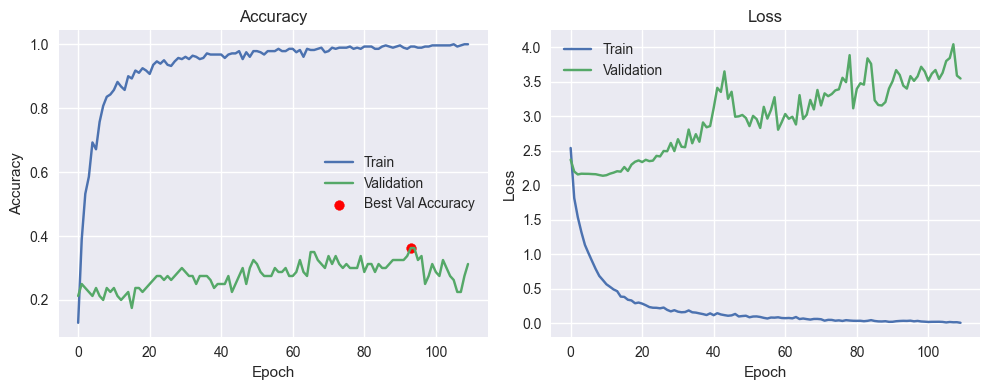

In [66]:
# YOUR CODE HERE!
log_df = pd.read_csv('training_model.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

*The best validation accuracy is:*

In [67]:
# YOUR CODE HERE!
print('Best validation accuracy: {:.2f}% at epoch {}'.format(best_val_acc*100, best_val_acc_epoch))

Best validation accuracy: 36.25% at epoch 93


Evaluate the model over the test dataset. What is your test accuracy? Is it better or worse than the one in your validation set?

In [68]:
# YOUR CODE HERE!
test_loss, test_accuracy = model.evaluate(X_test_rs, y_test, verbose=1)

print('Test Loss: {:.4f}'.format(test_loss))
print('Test Accuracy: {:.4f}'.format(test_accuracy))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3146 - loss: 3.2079
Test Loss: 3.3741
Test Accuracy: 0.3000


*The test accuracy is worse than the validation one:*

In [71]:
# YOUR CODE HERE!
print('Validation accuracy at last epoch: {:.2f}%'.format(log_df['val_accuracy'].values[-1]*100))
print('Test accuracy: {:.2f}%'.format(test_accuracy*100))

Validation accuracy at last epoch: 31.25%
Test accuracy: 30.00%


*The difference between the accuracies is strongly determined by the unbalance during the training-validation-test split.
Some classes may be over-represented in the train set: in that case, the model will fit better to those classes, while being the opposite for under-represented classes.
This unbalance is going to influence the validation and test sets: the unbalances of these set differs from the one of the train set, so one of the sets will fit worse to the model.*

*In our case, validation accuracy (at last epoch) is higher than test accuracy, but it's not always the case: it is influenced by the randomness of the splitting process.*

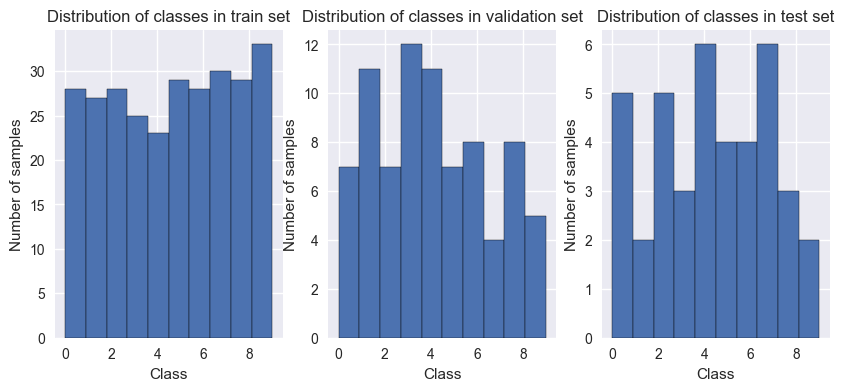

In [76]:
# YOUR CODE HERE!
plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.hist(y_train, edgecolor='black')
plt.title('Distribution of classes in train set')
plt.xlabel('Class')
plt.ylabel('Number of samples')

plt.subplot(1, 3, 2)
plt.hist(y_val, edgecolor='black')
plt.title('Distribution of classes in validation set')
plt.xlabel('Class')
plt.ylabel('Number of samples')

plt.subplot(1, 3, 3)
plt.hist(y_test, edgecolor='black')
plt.title('Distribution of classes in test set')
plt.xlabel('Class')
plt.ylabel('Number of samples')
plt.show()

Now restore the best weights using `model.load_weights` and evaluate again. Discuss the obtained results.

In [78]:
# YOUR CODE HERE!
model.load_weights(model_name)

test_loss_best, test_accuracy_best = model.evaluate(X_test_rs, y_test, verbose=1)

print('Test Loss with best weights: {:.4f}'.format(test_loss_best))
print('Test Accuracy with best weights: {:.2f}%'.format(test_accuracy_best*100))
print('Best validation accuracy: {:.2f}%'.format(best_val_acc*100))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4125 - loss: 3.0972
Test Loss with best weights: 3.2522
Test Accuracy with best weights: 40.00%
Best validation accuracy: 36.25%


*The test accuracy with the best weights is higher with respect to the case of using the last epoch parameters.
We observe overfitting, so the model, once it gets the the point of best validation accuracy, is unlikely to improve the performances even more: the validation accuracy starts oscillating within a certain range, which means that the last epoch is not necessarely the best one and it's not sure that it'll get higher than the best found.
Regarding this, considering the point of best validation accuracy is likely to produce a better test accuracy.*

*Considering the unbalance introduced in the previous answer, the improvement we notice in the validation accuracy is not the same we may appreciate in the test accuracy.
In our case, the test accuracy overcomes than the validation one.*

### **Exercise 4**: 1D-CNN Evaluation

Plot your confusion matrix for the validation set and for your test set. Discuss the obtained results.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


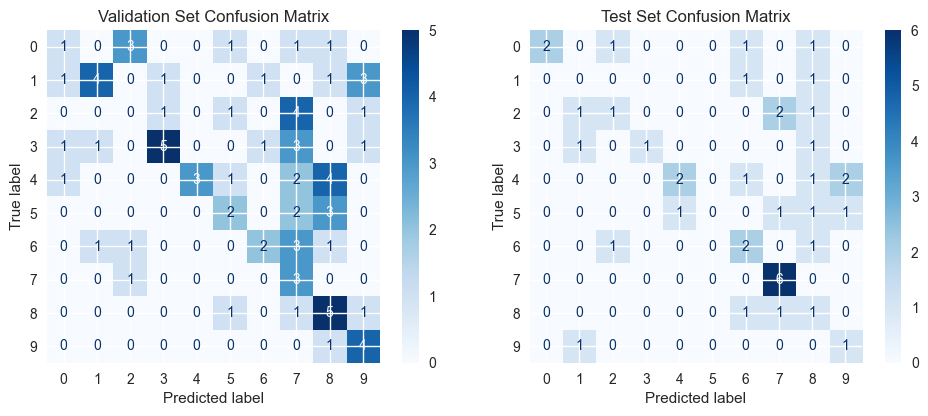

In [79]:
# YOUR CODE HERE!
y_val_pred = model.predict(X_val_rs).argmax(axis=1)
y_test_pred = model.predict(X_test_rs).argmax(axis=1)

val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Test Set Confusion Matrix")

plt.tight_layout()
plt.show()

*We can notice that both validation and test confusion matrixes display a similar distribution: both of them are incorrectly labelling the samples, associating almost all true labels into high predicted label values (such as 7, 8, 9).
We can appreciate that the highest labels are less mismatched with respect to the other classes.*

*This similarity shows consistency in the model.
On the other hand, this missclassification seems to be aligned with the classes distribution in the training set, which supports the previous observation.*

### **Exercise 5**: Time-Distributed 1D-CNN

In the previous 1D-CNN, each band of the Mel-spectrogram was treated as an independent channel. We want to continue using a similar 1D-CNN architecture but this time using a time-distributed model. Now the input will have several time steps (frames in this case) and 1 single channel.

Reshape your input X_train_rs to create a new input X_train_rss with dimensions (280, 216, 128, 1). You can use numpy's expand_dims.

In [81]:
# YOUR CODE HERE!
X_train_rss = np.expand_dims(X_train_rs, axis=-1)
X_val_rss = np.expand_dims(X_val_rs, axis=-1)
X_test_rss = np.expand_dims(X_test_rs, axis=-1)

print(f'Original size X_train_rs.shape=', X_train_rs.shape, '; X_val_rs.shape=', X_val_rs.shape, '; X_test_rs.shape=', X_test_rs.shape)
print(f'New size X_train_rss.shape=X_train_rss.shape', X_train_rss.shape, '; X_val_rss.shape=', X_val_rss.shape, '; X_test_rss.shape=', X_test_rss.shape)

Original size X_train_rs.shape= (280, 216, 128) ; X_val_rs.shape= (80, 216, 128) ; X_test_rs.shape= (40, 216, 128)
New size X_train_rss.shape=X_train_rss.shape (280, 216, 128, 1) ; X_val_rss.shape= (80, 216, 128, 1) ; X_test_rss.shape= (40, 216, 128, 1)


Expected output:
```
Original size X_train_rs.shape= (280, 216, 128) ; X_val_rs.shape= (80, 216, 128) ; X_test_rs.shape= (40, 216, 128)
New size X_train_rss.shape=X_train_rss.shape (280, 216, 128, 1) ; X_val_rss.shape= (80, 216, 128, 1) ; X_test_rss.shape= (40, 216, 128, 1)
```

Create your time-distributed network. A good thing of time-distributed networks is that the time-step dimension does not have to be fixed (it can be None). Thus, you can specify your input shape as:

input_shape = (None, 128, 1)



In [86]:
# YOUR CODE HERE!
modeltd = keras.Sequential([
    layers.Input(shape=(None, X_train_rs.shape[2], 1)),

    layers.TimeDistributed(layers.Conv1D(filters=16, kernel_size=9, activation='relu')),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.BatchNormalization()),

    layers.TimeDistributed(layers.Conv1D(filters=16, kernel_size=3, activation='relu')),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.BatchNormalization()),

    layers.TimeDistributed(layers.Conv1D(filters=32, kernel_size=3, activation='relu')),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.BatchNormalization()),
    layers.TimeDistributed(layers.Flatten()),

    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])

#Create a time distributed model
modeltd.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, None, 120, 16)  │           160 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, None, 60, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, None, 60, 16)   │            64 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, None, 58, 16)   │           784 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, None, 29, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, None, 29, 16)   │            64 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, None, 27, 32)   │         1,568 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, None, 14, 32)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_8              │ (None, None, 14, 32)   │           128 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_9              │ (None, None, 448)      │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 448)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │        14,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,466 (68.23 KB)

 Trainable params: 17,338 (67.73 KB)

 Non-trainable params: 128 (512.00 B)

Train the model using the same callbacks as before.

In [29]:
# YOUR CODE HERE!
# csv logger
csv_logger = CSVLogger('training_modeltd.log', append=False)

# early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=100)

# model checkpoint
model_name = 'best_modeltd.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

#store all these callbacks in a list, Callback list
callbacks = [csv_logger, early_stopping, model_checkpoint]

modeltd.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_td = modeltd.fit(
    X_train_rss, y_train,
    validation_data=(X_val_rss, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.1329 - loss: 2.3278
Epoch 1: val_accuracy improved from -inf to 0.16250, saving model to best_modeltd.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 179s 8s/step - accuracy: 0.1357 - loss: 2.3215 - val_accuracy: 0.1625 - val_loss: 2.1988
Epoch 2/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3432 - loss: 2.0043
Epoch 2: val_accuracy improved from 0.16250 to 0.18750, saving model to best_modeltd.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.3414 - loss: 2.0036 - val_accuracy: 0.1875 - val_loss: 2.0844
Epoch 3/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3710 - loss: 1.8723
Epoch 3: val_accuracy did not improve from 0.18750
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.3750 - loss: 1.8688 - val_accuracy: 0.1625 - val_loss: 2.1114
Epoch 4/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4433 - loss: 1.7022
Epoch 4: val_accuracy improved from 0.18750 to 0.25000, saving model to best_modeltd.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.4454 - loss: 1.7009 - val_accuracy: 0.2500 - val_loss: 1.9546
Epoch 5/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.5536 - loss: 1.5399
Epoch 5: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.5521 - loss: 1.5392 - val_accuracy: 0.2000 - val_loss: 2.0080
Epoch 6/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.5469 - loss: 1.4674
Epoch 6: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.5518 - loss: 1.4576 - val_accuracy: 0.0875 - val_loss: 2.6200
Epoch 7/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6124 - loss: 1.2754
Epoch 7: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.6126 - loss: 1.2712 - val_accuracy: 0.1875 - val_loss: 3.0467
Epoch 8/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.5776 - loss: 1.1497
Epoch 8: val_accuracy did not improve from 0.25000
9/9 ━━━━━━━━

9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9629 - loss: 0.1546 - val_accuracy: 0.2750 - val_loss: 5.6838
Epoch 54/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9566 - loss: 0.1614
Epoch 54: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9560 - loss: 0.1625 - val_accuracy: 0.0875 - val_loss: 8.9028
Epoch 55/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9578 - loss: 0.1722
Epoch 55: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9588 - loss: 0.1711 - val_accuracy: 0.0750 - val_loss: 10.8081
Epoch 56/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9836 - loss: 0.1298
Epoch 56: val_accuracy did not improve from 0.27500
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9834 - loss: 0.1305 - val_accuracy: 0.1000 - val_loss: 9.1662
Epoch 57/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9696 - loss: 0.1703
Epoch 57: val_accuracy did not improve from 0.27500
9/9

9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9908 - loss: 0.0491 - val_accuracy: 0.2875 - val_loss: 7.5749
Epoch 92/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9992 - loss: 0.0467
Epoch 92: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9986 - loss: 0.0478 - val_accuracy: 0.2750 - val_loss: 7.4881
Epoch 93/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9902 - loss: 0.0592
Epoch 93: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9908 - loss: 0.0583 - val_accuracy: 0.0875 - val_loss: 15.5625
Epoch 94/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9957 - loss: 0.0421
Epoch 94: val_accuracy did not improve from 0.28750
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9954 - loss: 0.0435 - val_accuracy: 0.2750 - val_loss: 8.7706
Epoch 95/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9900 - loss: 0.0707
Epoch 95: val_accuracy did not improve from 0.28750
9/9

Plot the training history and the best validation accuracy result.

Best validation accuracy: 41.25% at epoch 20


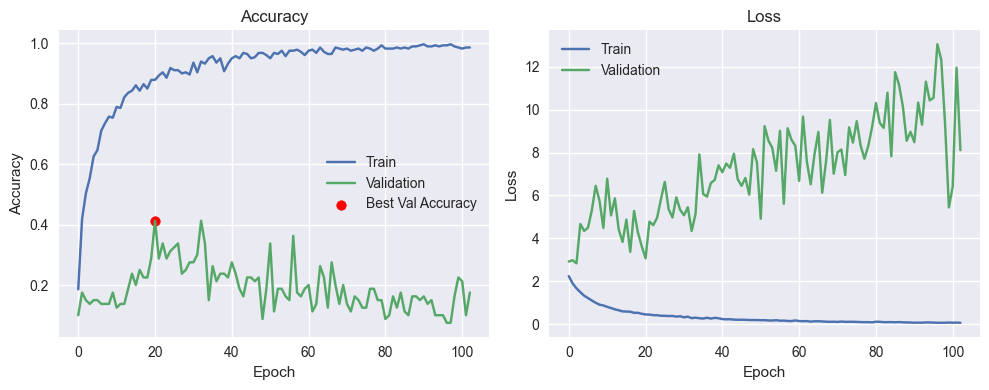

In [87]:
# YOUR CODE HERE!
log_df_td = pd.read_csv('training_modeltd.log')
best_val_acc_td = max(log_df_td['val_accuracy'])
best_val_acc_epoch_td = log_df_td['epoch'][log_df_td['val_accuracy'] == best_val_acc_td].values[0]

print('Best validation accuracy: {:.2f}% at epoch {}'.format(best_val_acc_td*100, best_val_acc_epoch_td))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df_td['epoch'], log_df_td['accuracy'], label='Train')
plt.plot(log_df_td['epoch'], log_df_td['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch_td, best_val_acc_td, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df_td['epoch'], log_df_td['loss'], label='Train')
plt.plot(log_df_td['epoch'], log_df_td['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Load the optimal weights (from early stopping) and plot the validation and test confusion matrices:

3/3 ━━━━━━━━━━━━━━━━━━━━ 27s 7s/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


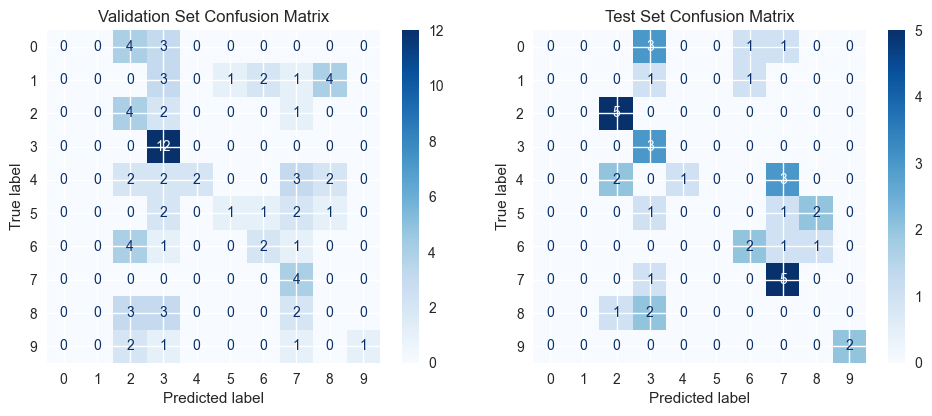

In [ ]:
# YOUR CODE HERE!
modeltd.load_weights('best_modeltd.h5')

y_val_pred = modeltd.predict(X_val_rss).argmax(axis=1)
y_test_pred = modeltd.predict(X_test_rss).argmax(axis=1)

val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

*We may notice how the model tends to associate any true label to specific predicted labels (such as 2, 3, 7), which consequently are the best predicted classes.
Both validation and test confusion matrixes exhibit the same distribution.*

*With this new model, some classes are excluded from the prediction (such as 0, 1, 4, 9), while most of the predicted classes are focused in specific labels (such as 2, 3).*

**TO REVIEW**
Check why this one is different and compare with previous one.

### **Exercise 6**: Performance metrics

Use sklearn "classification_report" to analyze the performance of the classifier for each class in terms of Precision, Recall and F1.

Show the classification report for validation set. Discuss the results.

In [89]:
print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         7
           1       0.00      0.00      0.00        11
           2       0.21      0.57      0.31         7
           3       0.41      1.00      0.59        12
           4       1.00      0.18      0.31        11
           5       0.50      0.14      0.22         7
           6       0.40      0.25      0.31         8
           7       0.27      1.00      0.42         4
           8       0.00      0.00      0.00         8
           9       1.00      0.20      0.33         5

    accuracy                           0.33        80
   macro avg       0.38      0.33      0.25        80
weighted avg       0.38      0.33      0.25        80



c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(resu

DISCUSSION HERE!

Show the classification report for the test set. Discuss the results.

In [90]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.00      0.00      0.00         2
           2       0.62      1.00      0.77         5
           3       0.27      1.00      0.43         3
           4       1.00      0.17      0.29         6
           5       0.00      0.00      0.00         4
           6       0.50      0.50      0.50         4
           7       0.45      0.83      0.59         6
           8       0.00      0.00      0.00         3
           9       1.00      1.00      1.00         2

    accuracy                           0.45        40
   macro avg       0.39      0.45      0.36        40
weighted avg       0.42      0.45      0.36        40



c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(resu

DISCUSSION HERE!

### **Exercise 7**: Hybrid CNN-RNN

In this last exercise we are going to mix our previous time-distributed model with a LSTM layer to create a Hybrid CNN-RNN architecture.

Adapt your previous time-distributed model to match the following summary:

In [34]:
# _________________________________________________________________
# Layer (type)                 Output Shape              Param #

# Time-Dist Conv1D             (None, None, 120, 16)     160
# _________________________________________________________________
# Time-Dist MaxPool1D 1D       (None, None, 60, 16)      0
# _________________________________________________________________
# Time-Dist Dropout (0.5)      (None, None, 60, 16)      0
# _________________________________________________________________
# Time-Dist Conv1D             (None, None, 58, 16)      784
# _________________________________________________________________
# Time-Dist MaxPool1D          (None, None, 29, 16)      0
# _________________________________________________________________
# Time-Dist Dropout (0.5)      (None, None, 29, 16)      0
# _________________________________________________________________
# Time-Dist Conv1D             (None, None, 27, 32)      1568
# _________________________________________________________________
# Time-Dist Dropout (0.5)      (None, None, 27, 32)      0
# _________________________________________________________________
# Time-Dist MaxPool1D          (None, None, 14, 32)      0
# _________________________________________________________________
# Time-Dist Flatten            (None, None, 448)         0
# _________________________________________________________________
# LSTM  (16 neurons)           (None, None, 16)          29760
# _________________________________________________________________
# Global Av. Pooling 1D        (None, 16)                0
# _________________________________________________________________
# Dropout (0.35)               (None, 16)                0
# _________________________________________________________________
# Dense                        (None, 10)                170

# Total params: 32,442
# Trainable params: 32,442
# Non-trainable params: 0
# _________________________________________________________________


In [91]:
# YOUR CODE HERE!
modelhy = keras.Sequential([
    layers.Input(shape=(None, X_train_rs.shape[2], 1)),

    layers.TimeDistributed(layers.Conv1D(filters=16, kernel_size=9, activation='relu')),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.Dropout(0.5)),

    layers.TimeDistributed(layers.Conv1D(filters=16, kernel_size=3, activation='relu')),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.Dropout(0.5)),

    layers.TimeDistributed(layers.Conv1D(filters=32, kernel_size=3, activation='relu')),
    layers.TimeDistributed(layers.Dropout(0.5)),
    layers.TimeDistributed(layers.MaxPooling1D(pool_size=2, padding='same')),

    layers.TimeDistributed(layers.Flatten()),
    layers.LSTM(16, return_sequences=True),
    layers.GlobalAveragePooling1D(),

    layers.Dropout(0.35),
    layers.Dense(10, activation='softmax')
])

#Create a time distributed model
modelhy.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_10             │ (None, None, 120, 16)  │           160 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_11             │ (None, None, 60, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_12             │ (None, None, 60, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_13             │ (None, None, 58, 16)   │           784 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_14             │ (None, None, 29, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_15             │ (None, None, 29, 16)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_16             │ (None, None, 27, 32)   │         1,568 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_17             │ (None, None, 27, 32)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_18             │ (None, None, 14, 32)   │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_19             │ (None, None, 448)      │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 16)       │        29,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,442 (126.73 KB)

 Trainable params: 32,442 (126.73 KB)

 Non-trainable params: 0 (0.00 B)

Train the network using the same procedure as in previous tasks.

In [97]:
# csv logger
csv_logger = CSVLogger('training_modelhy.log', append=False)

# early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=100)

# model checkpoint
model_name = 'best_modelhy.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

#store all these callbacks in a list, Callback list
callbacks = [csv_logger, early_stopping, model_checkpoint]

modelhy.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# YOUR CODE HERE!
history_hy = modelhy.fit(
    X_train_rss, y_train,
    validation_data=(X_val_rss, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.1622 - loss: 2.2715
Epoch 1: val_accuracy improved from -inf to 0.15000, saving model to best_modelhy.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 143s 7s/step - accuracy: 0.1627 - loss: 2.2691 - val_accuracy: 0.1500 - val_loss: 2.2235
Epoch 2/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.2829 - loss: 2.1339
Epoch 2: val_accuracy improved from 0.15000 to 0.22500, saving model to best_modelhy.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.2814 - loss: 2.1339 - val_accuracy: 0.2250 - val_loss: 2.1777
Epoch 3/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3366 - loss: 2.0592
Epoch 3: val_accuracy improved from 0.22500 to 0.30000, saving model to best_modelhy.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.3373 - loss: 2.0574 - val_accuracy: 0.3000 - val_loss: 2.1168
Epoch 4/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3733 - loss: 1.9740
Epoch 4: val_accuracy improved from 0.30000 to 0.32500, saving model to best_modelhy.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.3745 - loss: 1.9729 - val_accuracy: 0.3250 - val_loss: 2.0599
Epoch 5/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.3685 - loss: 1.8930
Epoch 5: val_accuracy did not improve from 0.32500
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.3713 - loss: 1.8901 - val_accuracy: 0.3125 - val_loss: 2.0023
Epoch 6/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4268 - loss: 1.7567
Epoch 6: val_accuracy improved from 0.32500 to 0.35000, saving model to best_modelhy.h5


...

9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.7755 - loss: 0.6105 - val_accuracy: 0.6875 - val_loss: 1.1200
Epoch 206/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7938 - loss: 0.6055
Epoch 206: val_accuracy did not improve from 0.68750
9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.7955 - loss: 0.6046 - val_accuracy: 0.6875 - val_loss: 1.0940
Epoch 207/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8016 - loss: 0.5774
Epoch 207: val_accuracy did not improve from 0.68750
9/9 ━━━━━━━━━━━━━━━━━━━━ 52s 6s/step - accuracy: 0.8043 - loss: 0.5727 - val_accuracy: 0.6875 - val_loss: 1.0674
Epoch 208/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8440 - loss: 0.5093
Epoch 208: val_accuracy did not improve from 0.68750
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8446 - loss: 0.5092 - val_accuracy: 0.6750 - val_loss: 1.1030
Epoch 209/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7994 - loss: 0.5934
Epoch 209: val_accuracy did not improve from 0.68

9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.7766 - loss: 0.6322 - val_accuracy: 0.7000 - val_loss: 1.1373
Epoch 217/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7935 - loss: 0.6208
Epoch 217: val_accuracy did not improve from 0.70000
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.7949 - loss: 0.6200 - val_accuracy: 0.6750 - val_loss: 1.1632
Epoch 218/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7857 - loss: 0.5886
Epoch 218: val_accuracy did not improve from 0.70000
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.7850 - loss: 0.5896 - val_accuracy: 0.6500 - val_loss: 1.2004
Epoch 219/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7581 - loss: 0.7696
Epoch 219: val_accuracy did not improve from 0.70000
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.7587 - loss: 0.7692 - val_accuracy: 0.6500 - val_loss: 1.2505
Epoch 220/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7743 - loss: 0.7515
Epoch 220: val_accuracy did not improve from 0.70

9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8553 - loss: 0.4817 - val_accuracy: 0.7125 - val_loss: 1.0960
Epoch 256/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8372 - loss: 0.5276
Epoch 256: val_accuracy did not improve from 0.71250
9/9 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.8392 - loss: 0.5224 - val_accuracy: 0.6875 - val_loss: 1.0987
Epoch 257/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8631 - loss: 0.4598
Epoch 257: val_accuracy did not improve from 0.71250
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8611 - loss: 0.4647 - val_accuracy: 0.6750 - val_loss: 1.0683
Epoch 258/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7901 - loss: 0.5899
Epoch 258: val_accuracy did not improve from 0.71250
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.7908 - loss: 0.5861 - val_accuracy: 0.6750 - val_loss: 1.0523
Epoch 259/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7659 - loss: 0.5986
Epoch 259: val_accuracy did not improve from 0.71

9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8212 - loss: 0.5240 - val_accuracy: 0.7250 - val_loss: 1.1110
Epoch 314/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8336 - loss: 0.4485
Epoch 314: val_accuracy improved from 0.72500 to 0.73750, saving model to best_modelhy.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8345 - loss: 0.4474 - val_accuracy: 0.7375 - val_loss: 1.0854
Epoch 315/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8403 - loss: 0.4606
Epoch 315: val_accuracy did not improve from 0.73750
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8391 - loss: 0.4637 - val_accuracy: 0.7125 - val_loss: 1.0999
Epoch 316/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8293 - loss: 0.5012
Epoch 316: val_accuracy did not improve from 0.73750
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8296 - loss: 0.5034 - val_accuracy: 0.7125 - val_loss: 1.1183
Epoch 317/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8440 - loss: 0.4871
Epoch 317: val_accuracy did not improve from 0.73750
9/9 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8425 - loss: 0.4863 - val_accuracy: 0.7125 - val_loss: 1.0750
Epoch 318/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8976 - loss: 0.3838
Epoch 318: val_accuracy did not improve from 0.73

Plot the training history and evaluate the model using the optimal weights (from early stopping).

NOTE: For the evaluation, compare the validation/test loss and accuracy, display the confusion matrices and show the classification reports.
Discuss your results.

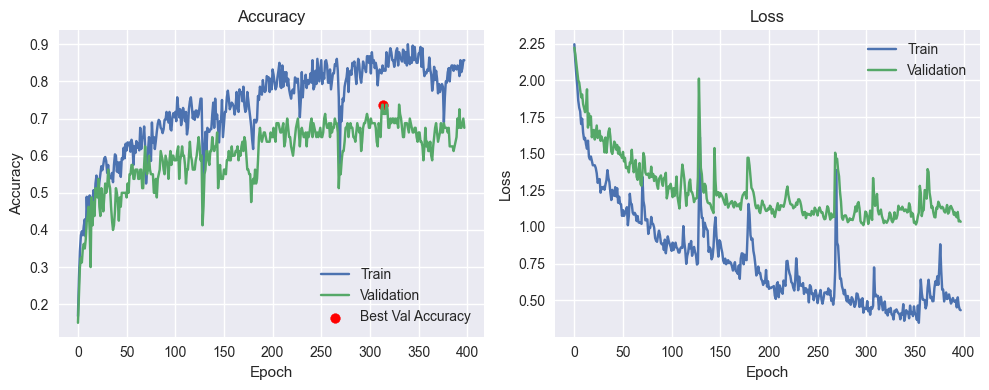

In [92]:
# YOUR CODE HERE!
log_df_hy = pd.read_csv('training_modelhy.log')
best_val_acc_hy = max(log_df_hy['val_accuracy'])
best_val_acc_epoch_hy = log_df_hy['epoch'][log_df_hy['val_accuracy'] == best_val_acc_hy].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df_hy['epoch'], log_df_hy['accuracy'], label='Train')
plt.plot(log_df_hy['epoch'], log_df_hy['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch_hy, best_val_acc_hy, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df_hy['epoch'], log_df_hy['loss'], label='Train')
plt.plot(log_df_hy['epoch'], log_df_hy['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


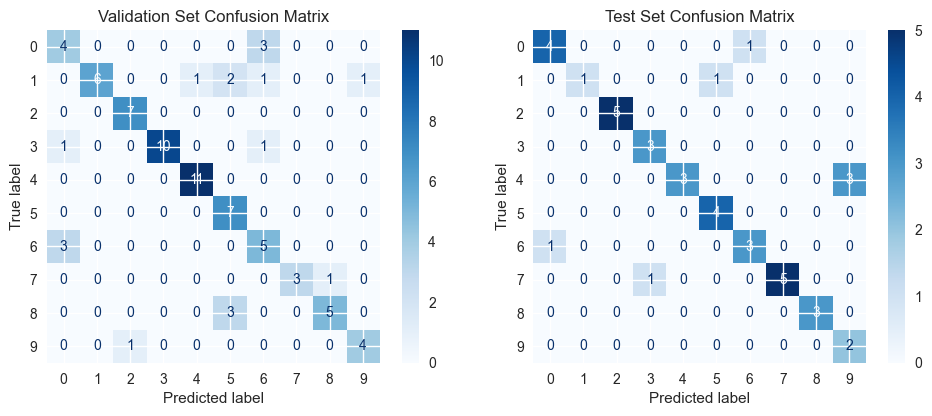

In [95]:
# YOUR CODE HERE!
modelhy.load_weights('best_modelhy.h5')

y_val_pred = modelhy.predict(X_val_rss).argmax(axis=1)
y_test_pred = modelhy.predict(X_test_rss).argmax(axis=1)

val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [98]:
# YOUR CODE HERE!
##Add validation
test_loss_best, test_accuracy_best = modelhy.evaluate(X_test_rss, y_test, verbose=1)

print('Test Loss with best weights: {:.4f}'.format(test_loss_best))
print('Test Accuracy with best weights: {:.4f}'.format(test_accuracy_best))

2/2 ━━━━━━━━━━━━━━━━━━━━ 19s 70ms/step - accuracy: 0.8417 - loss: 0.4682
Test Loss with best weights: 0.5320
Test Accuracy with best weights: 0.8250


In [99]:
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.50      0.57      0.53         7
           1       1.00      0.55      0.71        11
           2       0.88      1.00      0.93         7
           3       1.00      0.83      0.91        12
           4       0.92      1.00      0.96        11
           5       0.58      1.00      0.74         7
           6       0.50      0.62      0.56         8
           7       1.00      0.75      0.86         4
           8       0.83      0.62      0.71         8
           9       0.80      0.80      0.80         5

    accuracy                           0.78        80
   macro avg       0.80      0.78      0.77        80
weighted avg       0.82      0.78      0.78        80

              precision    recall  f1-score   support

           0       0.80      0.80      0.80         5
           1       1.00      0.50      0.67         2
           2       1.00      1.00      1.00         5
           3       0.75 

DISCUSSION HERE!

### **Exercise 8**: 2D CNN Experiment

Now, lets repeat the experiments but using a 2D CNN approach with the following proposed structure:

```
1.	Conv2D (16 filters, 3×3, ReLU, same padding)
2.	MaxPooling2D (2×2, same padding)
3.	BatchNormalization
4.	Conv2D (16 filters, 3×3, ReLU, same padding)
5.	MaxPooling2D (2×2, same padding)
6.	BatchNormalization
7.	Conv2D (32 filters, 3×3, ReLU, same padding)
8.	MaxPooling2D (2×2, same padding)
9.	BatchNormalization
10.	Flatten
11.	Dense (32 units, ReLU)
12.	Dense (10 units, Softmax) → Final classification layer for 10 classes
```

Develop the model, train it, evaluate it and discuss the results using the same procedure than in previous tasks:

In [100]:
modelcnn = keras.Sequential([
    layers.Input(shape=(X_train_rs.shape[1], X_train_rs.shape[2], 1)),  # Imagen 2D con canal único

    # Bloque 1
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.BatchNormalization(),

    # Bloque 2
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.BatchNormalization(),

    # Bloque 3
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.BatchNormalization(),

    # Clasificación
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 clases
])

# Resumen del modelo
modelcnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 216, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 108, 64, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 108, 64, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 108, 64, 16)    │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 54, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 54, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 27, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 27, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │       442,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 450,106 (1.72 MB)

 Trainable params: 449,978 (1.72 MB)

 Non-trainable params: 128 (512.00 B)

In [101]:
csv_logger = CSVLogger('training_modelcnn.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=100)

model_name = 'best_modelcnn.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

modelcnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# YOUR CODE HERE!
history_cnn = modelcnn.fit(
    X_train_rs, y_train,
    validation_data=(X_val_rs, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.1524 - loss: 2.8600
Epoch 1: val_accuracy improved from -inf to 0.30000, saving model to best_modelcnn.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.1589 - loss: 2.8484 - val_accuracy: 0.3000 - val_loss: 7.9586
Epoch 2/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.3978 - loss: 1.6221
Epoch 2: val_accuracy improved from 0.30000 to 0.35000, saving model to best_modelcnn.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.4006 - loss: 1.6170 - val_accuracy: 0.3500 - val_loss: 5.5932
Epoch 3/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5610 - loss: 1.3086
Epoch 3: val_accuracy improved from 0.35000 to 0.37500, saving model to best_modelcnn.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.5616 - loss: 1.3096 - val_accuracy: 0.3750 - val_loss: 4.5606
Epoch 4/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5605 - loss: 1.2275
Epoch 4: val_accuracy improved from 0.37500 to 0.38750, saving model to best_modelcnn.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.5655 - loss: 1.2205 - val_accuracy: 0.3875 - val_loss: 4.1565
Epoch 5/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7363 - loss: 0.9322
Epoch 5: val_accuracy improved from 0.38750 to 0.43750, saving model to best_modelcnn.h5


...

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.4875 - val_loss: 2.1700
Epoch 56/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 1.0000 - loss: 0.0035
Epoch 56: val_accuracy did not improve from 0.48750
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.4625 - val_loss: 2.1473
Epoch 57/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 1.0000 - loss: 0.0019
Epoch 57: val_accuracy did not improve from 0.48750
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.4750 - val_loss: 2.1583
Epoch 58/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0013   
Epoch 58: val_accuracy did not improve from 0.48750
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.4750 - val_loss: 2.1701
Epoch 59/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0013
Epoch 59: val_accuracy did not improve fr

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.9881 - loss: 0.0177 - val_accuracy: 0.5250 - val_loss: 2.3761
Epoch 79/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0031
Epoch 79: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.3500 - val_loss: 3.1858
Epoch 80/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 0.0037
Epoch 80: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 1.0000 - loss: 0.0038 - val_accuracy: 0.4875 - val_loss: 2.4141
Epoch 81/1000
8/9 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 0.0030
Epoch 81: val_accuracy did not improve from 0.52500
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 1.0000 - loss: 0.0029 - val_accuracy: 0.4500 - val_loss: 2.6005
Epoch 82/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0029
Epoch 82: val_accuracy did not improve from 

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.5375 - val_loss: 2.2498
Epoch 88/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 1.0000 - loss: 5.7938e-04
Epoch 88: val_accuracy improved from 0.53750 to 0.55000, saving model to best_modelcnn.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 1.0000 - loss: 5.9521e-04 - val_accuracy: 0.5500 - val_loss: 2.2549
Epoch 89/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 7.5805e-04
Epoch 89: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 1.0000 - loss: 7.7840e-04 - val_accuracy: 0.5500 - val_loss: 2.2705
Epoch 90/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 8.1911e-04
Epoch 90: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 1.0000 - loss: 8.1498e-04 - val_accuracy: 0.5500 - val_loss: 2.2631
Epoch 91/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 9.8849e-04
Epoch 91: val_accuracy did not improve from 0.55000
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 1.0000 - loss: 9.4921e-04 - val_accuracy: 0.5375 - val_loss: 2.2668
Epoch 92/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 4.9558e-04
Epoch 92: va

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 1.0000 - loss: 3.4381e-04 - val_accuracy: 0.5625 - val_loss: 2.2571
Epoch 94/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 9.7528e-04
Epoch 94: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 1.0000 - loss: 9.7829e-04 - val_accuracy: 0.5625 - val_loss: 2.2889
Epoch 95/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 6.0634e-04
Epoch 95: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 1.0000 - loss: 6.1387e-04 - val_accuracy: 0.5375 - val_loss: 2.3164
Epoch 96/1000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 4.7398e-04
Epoch 96: val_accuracy did not improve from 0.56250
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 1.0000 - loss: 4.7185e-04 - val_accuracy: 0.5500 - val_loss: 2.3115
Epoch 97/1000
8/9 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 4.9798e-04
Epoch 97: va

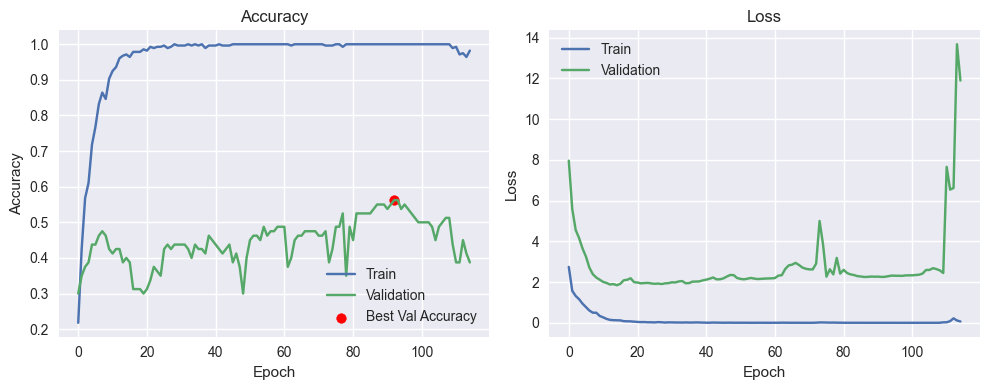

In [102]:
# YOUR CODE HERE!
log_df_cnn = pd.read_csv('training_modelcnn.log')
best_val_acc_cnn = max(log_df_cnn['val_accuracy'])
best_val_acc_epoch_cnn = log_df_cnn['epoch'][log_df_cnn['val_accuracy'] == best_val_acc_cnn].values[0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(log_df_cnn['epoch'], log_df_cnn['accuracy'], label='Train')
plt.plot(log_df_cnn['epoch'], log_df_cnn['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch_cnn, best_val_acc_cnn, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df_cnn['epoch'], log_df_cnn['loss'], label='Train')
plt.plot(log_df_cnn['epoch'], log_df_cnn['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


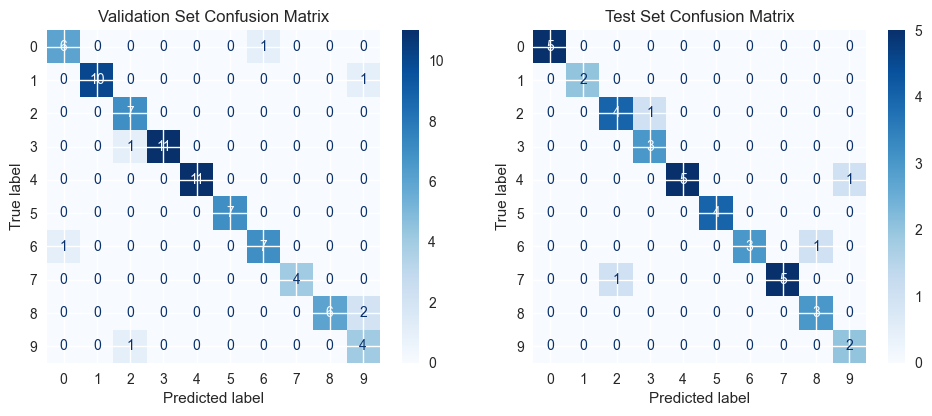

In [103]:
modelcnn.load_weights('best_modelcnn.h5')

y_val_pred = modelcnn.predict(X_val_rss).argmax(axis=1)
y_test_pred = modelcnn.predict(X_test_rss).argmax(axis=1)

val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=np.unique(y_train)).plot(cmap='Blues', ax=plt.gca())
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [104]:
# YOUR CODE HERE!
val_loss_best, val_accuracy_best = modelcnn.evaluate(X_val_rs, y_val, verbose=1)

print('Validation Loss with best weights: {:.4f}'.format(val_loss_best))
print('Validation Accuracy with best weights: {:.4f}'.format(val_accuracy_best))


test_loss_best, test_accuracy_best = modelcnn.evaluate(X_test_rs, y_test, verbose=1)

print('Test Loss with best weights: {:.4f}'.format(test_loss_best))
print('Test Accuracy with best weights: {:.4f}'.format(test_accuracy_best))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8977 - loss: 0.4389 
Validation Loss with best weights: 0.3888
Validation Accuracy with best weights: 0.9125
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9021 - loss: 0.3089
Test Loss with best weights: 0.3406
Test Accuracy with best weights: 0.9000


In [105]:
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86         7
           1       1.00      0.91      0.95        11
           2       0.78      1.00      0.88         7
           3       1.00      0.92      0.96        12
           4       1.00      1.00      1.00        11
           5       1.00      1.00      1.00         7
           6       0.88      0.88      0.88         8
           7       1.00      1.00      1.00         4
           8       1.00      0.75      0.86         8
           9       0.57      0.80      0.67         5

    accuracy                           0.91        80
   macro avg       0.91      0.91      0.90        80
weighted avg       0.93      0.91      0.92        80

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         2
           2       0.80      0.80      0.80         5
           3       0.75 

DISCUSSION HERE!